### Dataset Overview

A brain tumor is an abnormal growth of cells within the brain. Due to the rigid structure of the skull, any abnormal growth can increase intracranial pressure and potentially lead to severe neurological damage. Early detection and accurate classification of brain tumors are critical for selecting appropriate treatment strategies and improving patient outcomes.

This dataset is designed to support research in medical image analysis and deep learning–based brain tumor classification using MRI scans.


### Dataset Description

The dataset contains 7,200 human brain MRI images categorized into four classes:

- Glioma
- Meningioma
- Pituitary tumor
- No tumor

The dataset is structured into training and testing sets with balanced class distributions.

<pre>
Training/
    glioma/        (1400 images)
    meningioma/    (1400 images)
    pituitary/     (1400 images)
    notumor/       (1400 images)

Testing/
    glioma/        (400 images)
    meningioma/    (400 images)
    pituitary/     (400 images)
    notumor/       (400 images)
</pre>    

### Model Architecture 

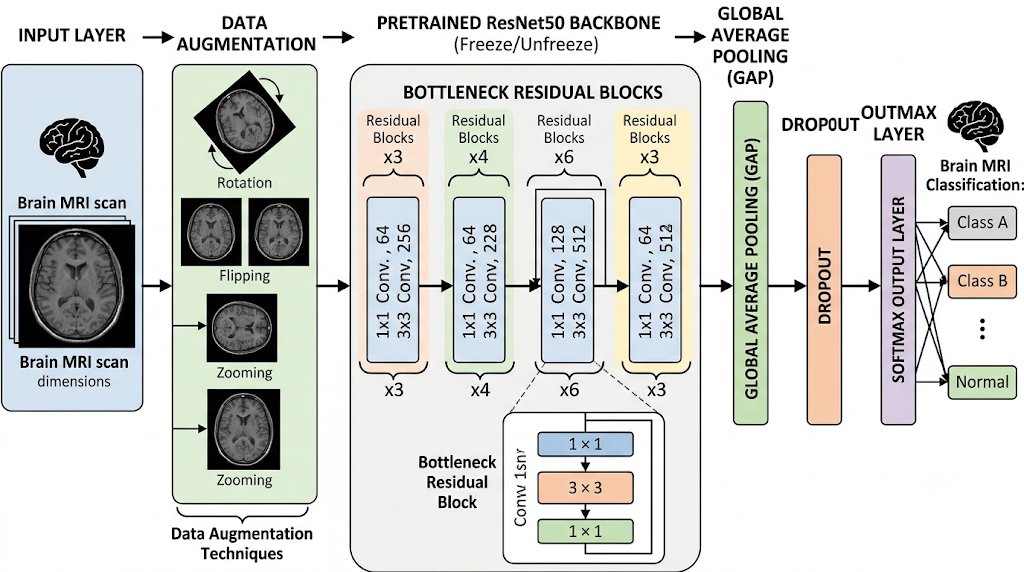

In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Import TensorFlow and Keras
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Import tools for splitting data and evaluating the model
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Set seeds to improve reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Dataset Local Path & Configure image dimensions and batch size
INPUT_DIR = Path("./brain_mri")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Print TensorFlow and GPU information
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


#### Load the dataset and create DataFrames for training and testing

In [4]:
#Load the dataset and create DataFrames for training and testing
def load_data(data_dir=INPUT_DIR):
    root = data_dir
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff"}
    def make_dataframe(split_name):
        split_dir = root / split_name
        if not split_dir.is_dir():
            raise FileNotFoundError(f"Dataset folder not found: {split_dir}")

        rows = []
        for category_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for image_path in sorted(category_dir.rglob("*")):
                if image_path.is_file() and image_path.suffix.lower() in image_extensions:
                    rows.append({
                        "Classes": category_dir.name,
                        "image_url": str(image_path.resolve()),
                    })

        return pd.DataFrame(rows, columns=["Classes", "image_url"])

    test_df = make_dataframe("Testing")
    train_df = make_dataframe("Training")
    return test_df, train_df

test_df, train_df = load_data()

### Finding lavel and LabelEncoding

In [5]:
# Load data and create DataFrames for training and testing with Label Encoding
from sklearn.preprocessing import LabelEncoder  
label_encoder = LabelEncoder()
label_encoder.fit(train_df["Classes"])
train_df["label"] = label_encoder.transform(train_df["Classes"])
test_df["label"] = label_encoder.transform(test_df["Classes"])

train_df


,Classes,image_url,label
0,glioma,E:\aiml\brain_mri\Training\glioma\Tr-gl_1.jpg,0
1,glioma,E:\aiml\brain_mri\Training\glioma\Tr-gl_10.jpg,0
2,glioma,E:\aiml\brain_mri\Training\glioma\Tr-gl_100.jpg,0
3,glioma,E:\aiml\brain_mri\Training\glioma\Tr-gl_1000.jpg,0
4,glioma,E:\aiml\brain_mri\Training\glioma\Tr-gl_1001.jpg,0
...,...,...,...
5595,pituitary,E:\aiml\brain_mri\Training\pituitary\Tr-pi_995...,3
5596,pituitary,E:\aiml\brain_mri\Training\pituitary\Tr-pi_996...,3
5597,pituitary,E:\aiml\brain_mri\Training\pituitary\Tr-pi_997...,3
5598,pituitary,E:\aiml\brain_mri\Training\pituitary\Tr-pi_998...,3


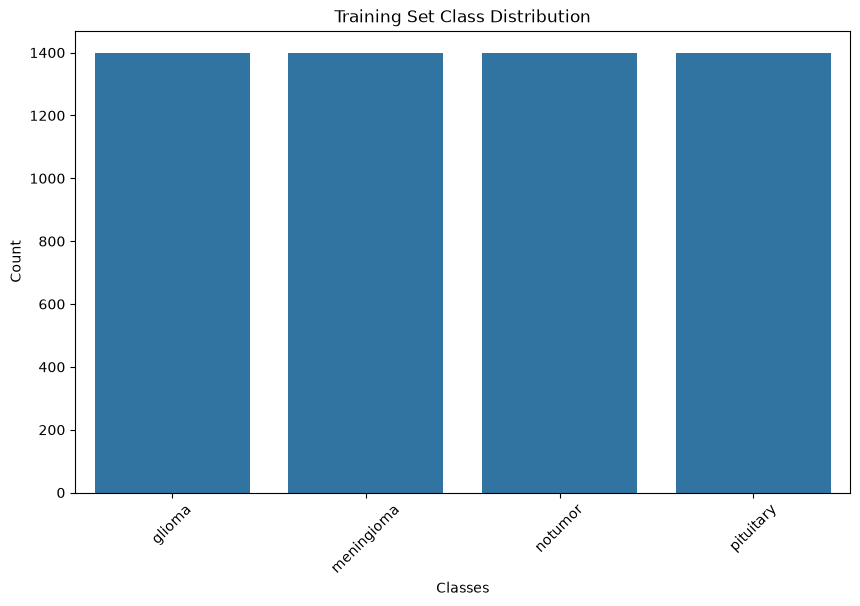

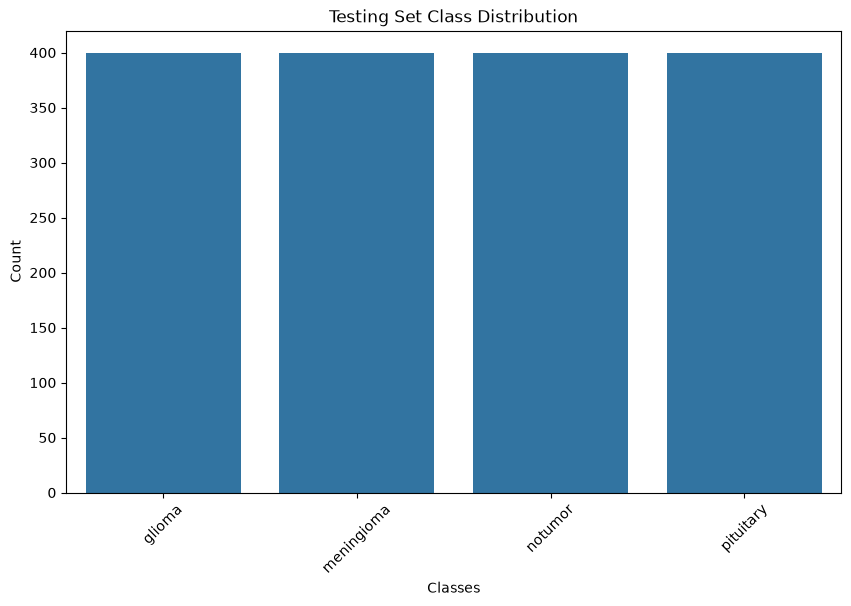

In [6]:
def plot_class_distribution(df, title):
    plt.figure(figsize=(10, 6))
    sns.countplot(x="Classes", data=df, order=df["Classes"].value_counts().index)
    plt.title(title)
    plt.xlabel("Classes")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

plot_class_distribution(train_df, "Training Set Class Distribution")
plot_class_distribution(test_df, "Testing Set Class Distribution")    

In [7]:
def load_data(data_dir=INPUT_DIR):
    root = data_dir
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff"}
    split_dirs = {
        "Testing": root / "Testing",
        "Training": root / "Training",
    }
    for split_dir in split_dirs.values():
        if not split_dir.is_dir():
            raise FileNotFoundError(f"Dataset folder not found: {split_dir}")

    class_names = sorted({
        class_dir.name
        for split_dir in split_dirs.values()
        for class_dir in split_dir.iterdir()
        if class_dir.is_dir()
    })
    class_to_label = {name: index for index, name in enumerate(class_names)}

    def make_dataframe(split_name):
        rows = []
        for class_dir in sorted(p for p in split_dirs[split_name].iterdir() if p.is_dir()):
            for image_path in sorted(class_dir.rglob("*")):
                if image_path.is_file() and image_path.suffix.lower() in image_extensions:
                    rows.append({
                        "Classes": class_dir.name,
                        "label": class_to_label[class_dir.name],
                        "image_url": str(image_path.resolve()),
                    })

        return pd.DataFrame(rows, columns=["Classes", "label", "image_url"])

    test_df = make_dataframe("Testing")
    train_df = make_dataframe("Training")

    return test_df, train_df

test_df, train_df = load_data()

In [8]:
test_df.head()

,Classes,label,image_url
0,glioma,0,E:\aiml\brain_mri\Testing\glioma\Te-gl_1.jpg
1,glioma,0,E:\aiml\brain_mri\Testing\glioma\Te-gl_10.jpg
2,glioma,0,E:\aiml\brain_mri\Testing\glioma\Te-gl_100.jpg
3,glioma,0,E:\aiml\brain_mri\Testing\glioma\Te-gl_101.jpg
4,glioma,0,E:\aiml\brain_mri\Testing\glioma\Te-gl_102.jpg


In [9]:
train_df.head()

,Classes,label,image_url
0,glioma,0,E:\aiml\brain_mri\Training\glioma\Tr-gl_1.jpg
1,glioma,0,E:\aiml\brain_mri\Training\glioma\Tr-gl_10.jpg
2,glioma,0,E:\aiml\brain_mri\Training\glioma\Tr-gl_100.jpg
3,glioma,0,E:\aiml\brain_mri\Training\glioma\Tr-gl_1000.jpg
4,glioma,0,E:\aiml\brain_mri\Training\glioma\Tr-gl_1001.jpg


### showing test and train data each

In [10]:
# Display the number of samples in each class for both training and testing datasets
class_counts = pd.DataFrame({
    "train": train_df["Classes"].value_counts(),
    "test": test_df["Classes"].value_counts(),
}).fillna(0).astype(int).sort_index()

print(class_counts)

            train  test
Classes                
glioma       1400   400
meningioma   1400   400
notumor      1400   400
pituitary    1400   400


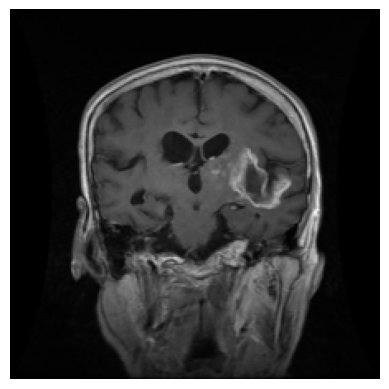

In [11]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
def showImage(image_path):
    with Image.open(image_path) as image:
        image_data = np.asarray(
            image.convert("RGB").resize(IMG_SIZE),
            dtype=np.uint8
        )
    plt.imshow(image_data)
    plt.axis("off")
    plt.show()
    return image_data

image_data = showImage(train_df.loc[6, "image_url"])

In [12]:
from PIL import Image
import numpy as np
def convert_image_data(image_path):
    with Image.open(image_path) as image:
        #Normalize the image data to have pixel values between 0 and 1
        image = image.convert("RGB").resize(IMG_SIZE)
        return np.asarray(image, dtype=np.float32) / 255.0


test_df["image_data"] = test_df["image_url"].apply(convert_image_data)
train_df["image_data"] = train_df["image_url"].apply(convert_image_data)

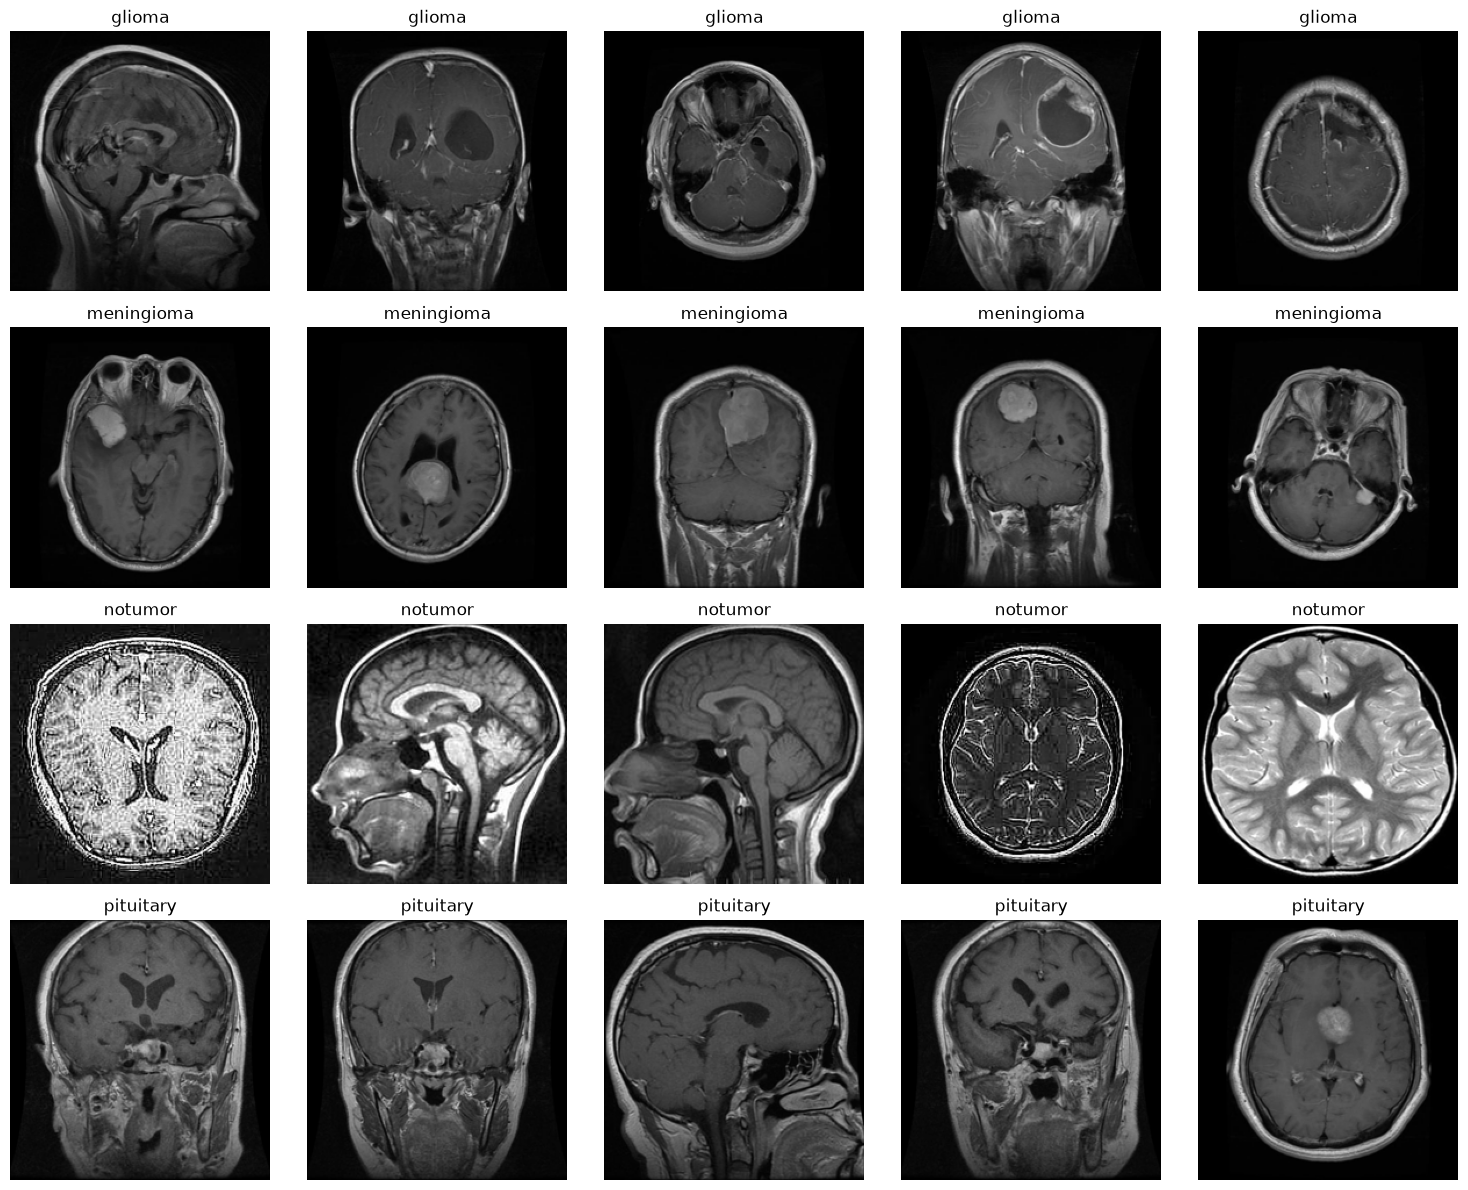

In [13]:
def showImageView(df, group_size=5, seed=None):
    classes = df["Classes"].dropna().unique()
    counts = df["Classes"].value_counts()
    too_small = counts[counts < group_size]
    if not too_small.empty:
        raise ValueError(
            f"Need at least {group_size} images per class; "
            f"not enough for: {too_small.index.tolist()}"
        )
        
    fig, axes = plt.subplots(
        len(classes),
        group_size,
        figsize=(15, 3 * len(classes)),
        squeeze=False,
    )

    for row, class_name in enumerate(classes):
        samples = df[df["Classes"] == class_name].sample(
            n=group_size,
            random_state=seed,
        )

        for col, (_, image_row) in enumerate(samples.iterrows()):
            ax = axes[row, col]
            ax.imshow(image_row["image_data"])
            ax.set_title(str(class_name))
            ax.axis("off")

    plt.tight_layout()
    plt.show()

showImageView(train_df, group_size=5, seed=SEED)

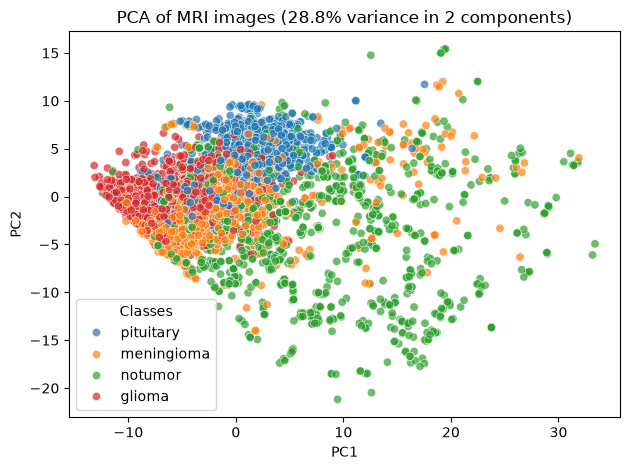

In [57]:
# Perform PCA on the training images to visualize the data in 2D space
from sklearn.decomposition import PCA
sample = train_df.sample(n=max(800, len(train_df)), random_state=42)
# Downsample each image by taking every 4th pixel, then flatten it
X = np.stack([
    image[::4, ::4, :].reshape(-1)
    for image in sample["image_data"]
]).astype(np.float32)

pca = PCA(n_components=2, svd_solver="randomized", random_state=42)
coords = pca.fit_transform(X)

plot_data = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "Classes": sample["Classes"].to_numpy(),
})

sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Classes", alpha=0.7)
plt.title(
    f"PCA of MRI images "
    f"({pca.explained_variance_ratio_.sum():.1%} variance in 2 components)"
)
plt.tight_layout()
plt.show()

### Train , validation and test splitting 

In [60]:
from pathlib import Path
import tensorflow as tf

INPUT_DIR = Path("./brain_mri")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# Split Training into training and validation sets; keep Testing untouched.
train_raw = tf.keras.utils.image_dataset_from_directory(
    INPUT_DIR / "Training",
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

val_raw = tf.keras.utils.image_dataset_from_directory(
    INPUT_DIR / "Training",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

test_raw = tf.keras.utils.image_dataset_from_directory(
    INPUT_DIR / "Testing",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False,
)

class_names = train_raw.class_names
assert test_raw.class_names == class_names, "Training and Testing class folders must match."

num_classes = len(class_names)
print("Classes:", class_names)

# ResNet50 preprocessing expects RGB pixel values in the 0–255 range.
def prepare_for_resnet(dataset):
    return dataset.map(
        lambda images, labels: (
            tf.keras.applications.resnet50.preprocess_input(images),
            labels,
        ),
        num_parallel_calls=AUTOTUNE,
    ).prefetch(AUTOTUNE)

train_ds = prepare_for_resnet(train_raw)
val_ds = prepare_for_resnet(val_raw)
test_ds = prepare_for_resnet(test_raw)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [15]:
#Checking Train Batch and Validation Batch
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:", tf.data.experimental.cardinality(val_ds).numpy())

Train batches: 140
Val batches: 35


In [16]:
#cheking Train data and validation data
train_count = sum(len(labels) for _, labels in train_ds)
val_count = sum(len(labels) for _, labels in val_ds)

print("Train images:", train_count)
print("Validation images:", val_count)
print("Total:", train_count + val_count)

Train images: 4480
Validation images: 1120
Total: 5600


### ResNet50 Model with Transfer Learning
#### Load the ResNet50 model without the top layer and with pre-trained ImageNet weights

In [17]:
#Model architecture
# ResNet50 backbone with a classification head for this dataset.
base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3),
)
base_model.trainable = False  # Train the new classification head first.

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

x = base_model(inputs, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.35)(x)

outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="brain_mri_resnet50")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()


Model: "brain_mri_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

###  RestNet50 Model with Augmentation Layers

In [ ]:

# Create moderate augmentation for MRI images
augmentation = models.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.08)
], name="augmentation")


# Load ResNet50 with pretrained ImageNet weights
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)

# Freeze the pretrained backbone for initial training
base_model.trainable = False

# Define the input tensor
inputs = layers.Input(shape=(*IMG_SIZE, 3))

# Apply augmentation during training only
x = augmentation(inputs)

# Apply ResNet50-specific input preprocessing
x = layers.Lambda(preprocess_input)(x)

# Extract pretrained visual features
x = base_model(x, training=False)

# Reduce spatial feature maps to a single vector
x = layers.GlobalAveragePooling2D()(x)

# Regularize the classifier
x = layers.Dropout(0.35)(x)

# Output probabilities for the four classes
outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

# Build the complete model
model = models.Model(inputs, outputs, name="brain_mri_resnet50")

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

### Train data & validation Training

In [19]:
# Stop training if validation loss no longer improves
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Save the checkpoint with the best validation loss
checkpoint = ModelCheckpoint(
    "best_resnet50.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Reduce learning rate when progress stalls
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Train the new classification layers
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        early_stopping,
        checkpoint,
        reduce_lr
    ]
)

Epoch 1/15


e:\aiml\pyvenvlib\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6911 - loss: 0.7927
Epoch 1: val_loss improved from None to 0.45148, saving model to best_resnet50.keras

Epoch 1: finished saving model to best_resnet50.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 223s 2s/step - accuracy: 0.6911 - loss: 0.7927 - val_accuracy: 0.8241 - val_loss: 0.4515 - learning_rate: 0.0010
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8181 - loss: 0.4614
Epoch 2: val_loss improved from 0.45148 to 0.31296, saving model to best_resnet50.keras

Epoch 2: finished saving model to best_resnet50.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 237s 2s/step - accuracy: 0.8181 - loss: 0.4614 - val_accuracy: 0.8991 - val_loss: 0.3130 - learning_rate: 0.0010
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8455 - loss: 0.3955
Epoch 3: val_loss did not improve from 0.31296
140/140 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.8455 - loss: 0.3955 - val_accuracy: 0.8679 - val_loss: 0.3400 - learning_rate: 0.0010


### Model Learning Curves Loss and Accurancy

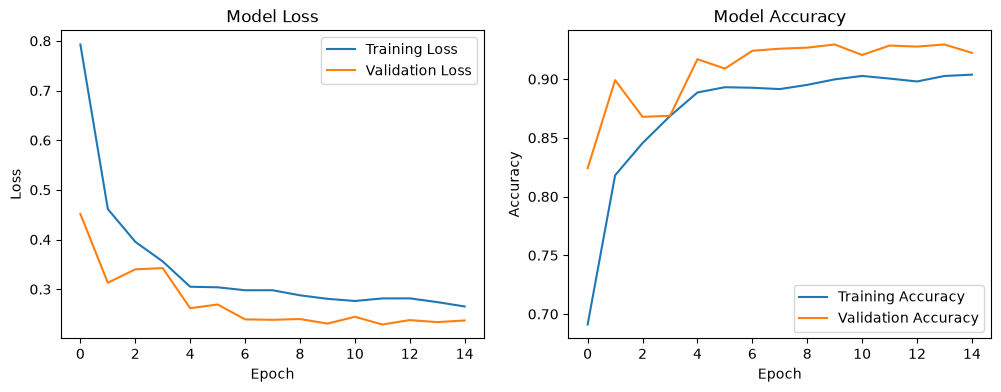

In [20]:
# Learning curves for training and validation loss and accuracy
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

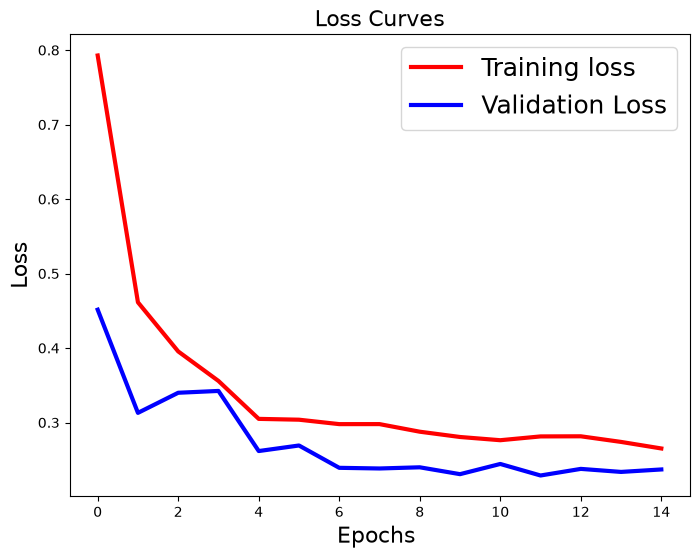

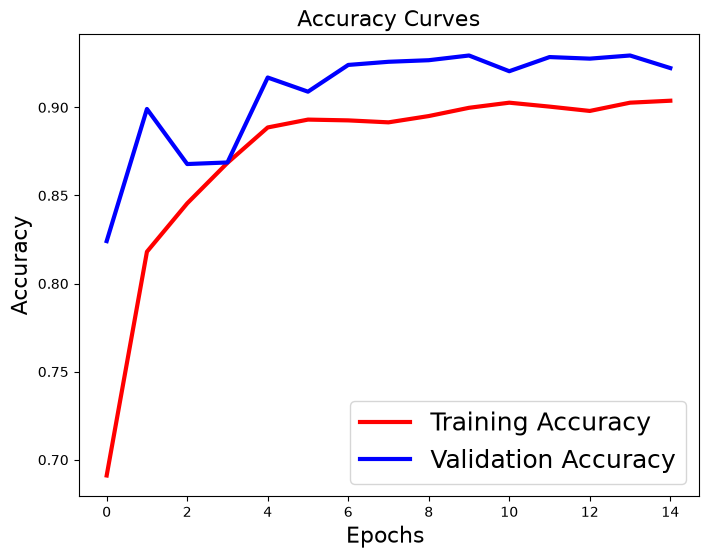

In [21]:
# Learning Curve
plt.figure(figsize=[8,6])
plt.plot(history.history['loss'],'r',linewidth=3.0)
plt.plot(history.history['val_loss'],'b',linewidth=3.0)
plt.legend(['Training loss', 'Validation Loss'],fontsize=18)
plt.xlabel('Epochs ',fontsize=16)
plt.ylabel('Loss',fontsize=16)
plt.title('Loss Curves',fontsize=16)
plt.show()

#Plot the Accuracy Curves
plt.figure(figsize=[8,6])
plt.plot(history.history['accuracy'],'r',linewidth=3.0)
plt.plot(history.history['val_accuracy'],'b',linewidth=3.0)
plt.legend(['Training Accuracy', 'Validation Accuracy'],fontsize=18)
plt.xlabel('Epochs ',fontsize=16)
plt.ylabel('Accuracy',fontsize=16)
plt.title('Accuracy Curves',fontsize=16)   
plt.show()

### Model Evaluation on Test Dataset

50/50 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.8706 - loss: 0.4593
140/140 ━━━━━━━━━━━━━━━━━━━━ 176s 1s/step - accuracy: 0.9230 - loss: 0.2214
Test loss:     0.4593
Test accuracy: 0.8706
Train loss:    0.2214
Train accuracy: 0.9230
50/50 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step
140/140 ━━━━━━━━━━━━━━━━━━━━ 176s 1s/step
Test Classification Report:
              precision    recall  f1-score   support

      glioma       0.90      0.73      0.81       400
  meningioma       0.81      0.79      0.80       400
     notumor       0.87      0.99      0.93       400
   pituitary       0.90      0.97      0.93       400

    accuracy                           0.87      1600
   macro avg       0.87      0.87      0.87      1600
weighted avg       0.87      0.87      0.87      1600

Train Classification Report:
              precision    recall  f1-score   support

      glioma       0.27      0.28      0.28      1140
  meningioma       0.26      0.23      0.24      1125
     notumor       0.25   

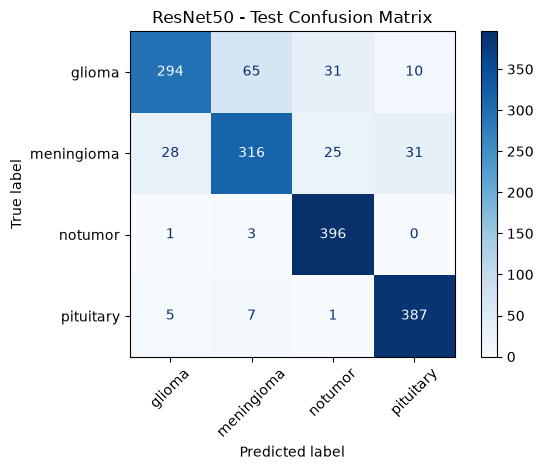

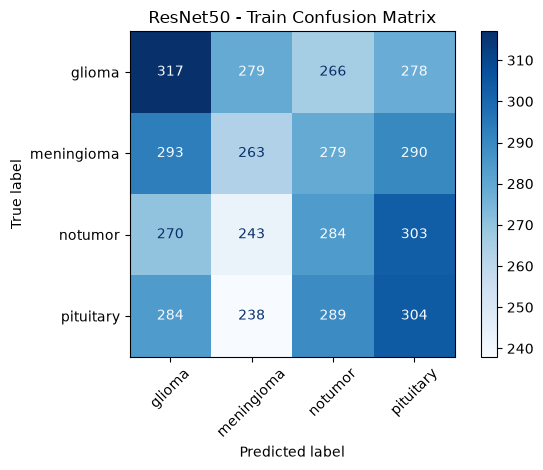

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
# Evaluate overall test loss and accuracy
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

train_loss, train_accuracy = model.evaluate(train_ds, verbose=1)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Train loss:    {train_loss:.4f}")
print(f"Train accuracy: {train_accuracy:.4f}")

# Get true labels and predicted probabilities
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Train data predictions
y_train_true = np.concatenate([labels.numpy() for _, labels in train_ds])
y_train_prob = model.predict(train_ds, verbose=1)
y_train_pred = np.argmax(y_train_prob, axis=1)


# Precision, recall, and F1-score for each class, plus overall accuracy
print("Test Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0,
))

print("Train Classification Report:")
print(classification_report(
    y_train_true,
    y_train_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0, 
))

# Test data Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
display.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("ResNet50 - Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Train data Confusion matrix
cm_train = confusion_matrix(y_train_true, y_train_pred, labels=range(len(class_names)))
display_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=class_names)
display_train.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("ResNet50 - Train Confusion Matrix")
plt.tight_layout()
plt.show()



Predicted class: glioma
Confidence: 99.70%


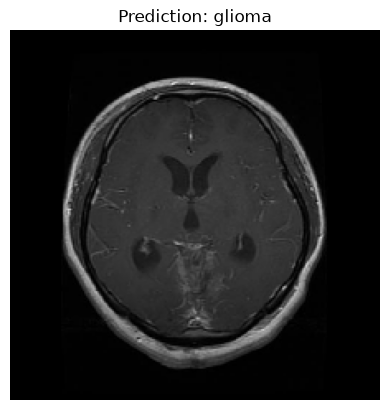

In [66]:
from pathlib import Path
from tensorflow.keras.utils import load_img, img_to_array

image_path = Path("./brain_mri/Testing/glioma/Te-gl_3.jpg")

image = load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
image_array = img_to_array(image)
image_array = tf.keras.applications.resnet50.preprocess_input(image_array)
image_batch = np.expand_dims(image_array, axis=0)

probabilities = model.predict(image_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))

print("Predicted class:", class_names[predicted_index])
print(f"Confidence: {probabilities[predicted_index]:.2%}")

plt.imshow(image)
plt.title(f"Prediction: {class_names[predicted_index]}")
plt.axis("off")
plt.show()

In [67]:
# Load the saved model and provide the preprocessing function
best_model = tf.keras.models.load_model(
    "best_resnet50.keras",
    custom_objects={
        "preprocess_input": preprocess_input
    },
    compile=False
)

### Summary

The solution was built around a brain tumor MRI dataset containing four classes: glioma, meningioma, pituitary tumor, and no tumor. The project used TensorFlow and Keras to preprocess the images, apply data augmentation, and train a ResNet50-based model with transfer learning. The training pipeline included normalization, resizing to 224×224, and optimization techniques such as early stopping, learning-rate reduction, and model checkpointing to improve convergence and prevent overfitting.

After training, the model was evaluated using loss, accuracy, precision, recall, F1-score, and confusion matrix analysis. The results showed that the model performed well on the test set, with a test loss of 0.4593 and test accuracy of 0.8706. This confirms that the model can effectively distinguish between the different brain tumor classes and can be used as a valuable tool for MRI-based tumor classification support.


### Conclusion

This solution successfully demonstrates the use of transfer learning for brain MRI classification. By leveraging a pre-trained ResNet50 model and adapting it to a four-class medical imaging task, the system was able to classify glioma, meningioma, pituitary tumor, and no tumor with strong accuracy. The model achieved a test accuracy of 87.06% and a training accuracy of 92.30%, indicating that it learned meaningful patterns from the MRI images and generalized reasonably well to unseen data.

Overall, the approach is effective, efficient, and suitable for medical image analysis tasks, especially when labeled data is limited. It provides a strong foundation for automated brain tumor screening and decision support. However, for real-world clinical use, further validation on larger and more diverse datasets, as well as expert medical review, would be necessary to ensure reliability and safety